In [2]:
#Install and import libraries

# Install packages if you need them
#%pip install pandas
%pip install seaborn
%pip install scipy

# Import packages
import pandas as pd
import seaborn as sns

# For getting exgaussian function parameters
from scipy.stats import exponnorm
import numpy as np

# For making quantile plots
import matplotlib.pyplot as plt

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [3]:
raw = pd.read_csv('/work/Experimental-Psycholinguistics/study/data1.csv', low_memory =False)
cols = ['Participant Code', 'correctResponse', 'duration', 'response', 'state', 'type', 'Version', 'word']
df = raw[cols] # make a new dataframe with only the columns in cols
df = df[df['type'] != 'practice']  # throw away the practice trials
df = df[df['response'] != 'next']
df = df[df['response'] != 'space']
df['correct'] = (df['response'] == df['correctResponse']).astype(int)     # make a new column with 0 or 1 for incorrect / correct
df = df[df['correct'] == 1]                                                # keep only the correct responses 
df = df.rename(columns={'duration': 'rt'})

In [6]:
dem = df[df['Version']=='M']
dem = dem[dem['type']=='E']
dem = dem.rename(columns={'rt': 'rtem'})
dh = df[df['type']=='H']
dh = dh.rename(columns={'rt': 'rth'})

In [8]:
clem = ['rtem']
dfem = dem[clem]
dfem.to_csv('em.csv')

In [9]:
clh = ['rth']
dfh = dh[clh]
dfh.to_csv('h.csv')

In [10]:
hem = pd.read_csv('/work/Experimental-Psycholinguistics/hem.csv')
hem

,rtem,rth
0,859.5,719.4
1,821.9,863.0
2,647.1,562.1
3,679.0,749.0
4,630.3,656.2
...,...,...
383,726.8,NaN
384,624.0,NaN
385,1103.6,NaN
386,560.8,NaN


In [11]:
from pingouin import ttest

ttest(hem['rth'], hem['rtem'], paired=True)

,T,dof,alternative,p_val,CI95,cohen_d,power,BF10
T_test,2.693594,363,two-sided,0.007397,"[9.0, 57.67]",0.183336,0.936819,2.076


In [12]:
hem.describe()

,rtem,rth
count,388.000000,364.000000
mean,700.410567,733.391099
std,160.594103,204.802116
min,298.400000,418.340000
25%,596.400000,598.900000
50%,675.000000,686.060000
75%,758.500000,793.440000
max,1604.000000,1655.800000


In [20]:
deh = df[df['Version']=='M']
deh = deh[deh['type'] != 'P']
deh = deh[deh['type'] != 'C']
deh = deh[deh['type'] != 'D']

In [21]:
deh_grouped = deh.groupby(['type','Version','state'])['rt'].mean().reset_index()
deh_grouped

,type,Version,state,rt
0,E,M,E,700.410567
1,H,M,E,733.391099


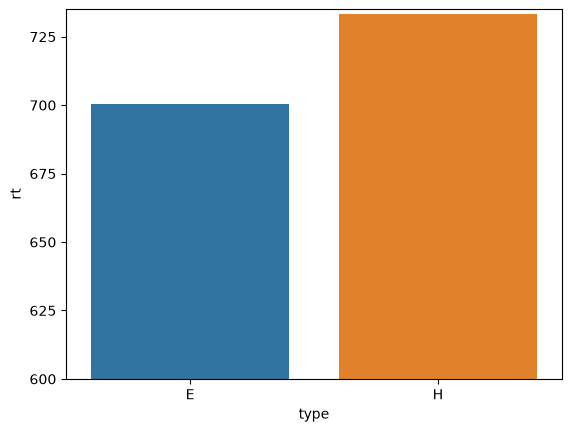

<Figure size 640x480 with 0 Axes>

In [27]:
sns.barplot(data=deh_grouped, x='type', y='rt', hue = 'type')            # make a barplot for E vs N for each version
plt.ylim(600, 735)  # Set the y-axis limits from 0 to 30
plt.yticks([600, 625, 650, 675, 700, 725])
plt.show()
sns.despine()